In [2]:
# ============================================================
# STEP 0 – Imports & paths
# ============================================================
import pandas as pd
import numpy as np
from pathlib import Path

from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_similarity

# Root folder = the one that contains: etfs/, metadata/, stocks/
ROOT = Path("/Users/yasmineleuch/Downloads/data_cleaned/")          # change if needed
META_PATH = ROOT / "metadata" / "metadata_clean.csv"
STOCKS_DIR = ROOT / "stocks"


In [3]:
# ============================================================
# STEP 1 – Load metadata (sectors, names, etc.)
# ============================================================
meta = pd.read_csv(META_PATH)

# Keep only the columns we care about for now
# (adapt if your metadata has slightly different names)
meta_small = meta[["symbol", "security_name", "Sector"]].copy()

print(meta_small.head())
print(meta_small.shape)


  symbol                                      security_name  \
0      A            Agilent Technologies, Inc. Common Stock   
1     AA                     Alcoa Corporation Common Stock   
2   AAAU                       Perth Mint Physical Gold ETF   
3   AACG  ATA Creativity Global - American Depositary Sh...   
4   AADR                AdvisorShares Dorsey Wright ADR ETF   

               Sector  
0          Healthcare  
1     Basic Materials  
2                 NaN  
3  Consumer Defensive  
4                 NaN  
(8049, 3)


In [4]:
# ============================================================
# STEP 2 – Load all stock price CSVs and merge with metadata
# ============================================================
all_dfs = []

for file in STOCKS_DIR.glob("*.csv"):
    df = pd.read_csv(file)
    
    # Add Symbol column from filename if not present
    if "Symbol" not in df.columns:
        df["Symbol"] = file.stem      # e.g. "A.csv" -> "A"
    
    # Parse dates – your example uses 18.11.1999 so dayfirst=True
    df["Date"] = pd.to_datetime(df["Date"], dayfirst=True)
    
    all_dfs.append(df)

prices = pd.concat(all_dfs, ignore_index=True)

print("Prices shape:", prices.shape)
print(prices.head())


Prices shape: (22140208, 10)
        Date  Weekday       Open       High        Low      Close  Adj Close  \
0 2016-01-08        4  19.162428  19.162428  19.114038  19.114038  11.411459   
1 2016-01-11        0  19.133394  19.230173  19.017258  19.017258  11.353675   
2 2016-01-12        1  19.113070  19.113070  19.103392  19.103392  11.405104   
3 2016-01-13        2  19.103392  19.103392  19.103392  19.103392  11.405104   
4 2016-01-14        3  19.065647  19.385021  18.968868  19.104361  11.405683   

        Volume Symbol  Volatility  
0  10300.00000    RIV    0.002525  
1  49600.00000    RIV    0.011128  
2   2300.00000    RIV    0.000506  
3   3900.31785    RIV    0.000000  
4  26100.00000    RIV    0.021827  


In [5]:
# ============================================================
# STEP 3 – Attach sector / security_name to each row
# ============================================================
full = prices.merge(
    meta_small,
    left_on="Symbol",
    right_on="symbol",
    how="left"
)

full = full.drop(columns=["symbol"])   # duplicate
print(full[["Date", "Symbol", "Adj Close", "Volume", "Sector"]].head())


        Date Symbol  Adj Close       Volume              Sector
0 2016-01-08    RIV  11.411459  10300.00000  Financial Services
1 2016-01-11    RIV  11.353675  49600.00000  Financial Services
2 2016-01-12    RIV  11.405104   2300.00000  Financial Services
3 2016-01-13    RIV  11.405104   3900.31785  Financial Services
4 2016-01-14    RIV  11.405683  26100.00000  Financial Services


In [6]:
# ============================================================
# STEP 4 – Restrict to recent history & compute daily returns
# (we'll use last 1 year to characterise each stock's "style")
# ============================================================
full = full.sort_values(["Symbol", "Date"])

# choose lookback window for style (1 year here)
cutoff = full["Date"].max() - pd.Timedelta(days=365)
recent = full[full["Date"] >= cutoff].copy()

# daily returns per stock
recent["ret_1d"] = recent.groupby("Symbol")["Adj Close"].pct_change()

print(recent[["Date", "Symbol", "Adj Close", "ret_1d"]].head(10))


               Date Symbol  Adj Close    ret_1d
19022264 2019-04-02   True       6.60       NaN
19022265 2019-04-03   True       6.58 -0.003030
19022266 2019-04-04   True       6.63  0.007599
19022267 2019-04-05   True       6.66  0.004525
19022268 2019-04-08   True       6.61 -0.007507
19022269 2019-04-09   True       6.50 -0.016641
19022270 2019-04-10   True       6.53  0.004615
19022271 2019-04-11   True       6.43 -0.015314
19022272 2019-04-12   True       6.44  0.001555
19022273 2019-04-15   True       6.33 -0.017081


In [7]:
# ============================================================
# STEP 5 – Build one feature vector per stock
# (risk, momentum, liquidity, sector)
# ============================================================

def stock_summary(df: pd.DataFrame) -> pd.Series:
    """
    df = data for ONE symbol over the lookback window
    """
    out = {}
    # risk
    out["mean_ret"] = df["ret_1d"].mean()
    out["vol_ret"] = df["ret_1d"].std()
    
    # momentum (if we have enough history, otherwise NaN)
    if len(df) > 21:
        out["mom_1m"] = df["Adj Close"].iloc[-1] / df["Adj Close"].iloc[-21] - 1
    else:
        out["mom_1m"] = np.nan
        
    if len(df) > 63:
        out["mom_3m"] = df["Adj Close"].iloc[-1] / df["Adj Close"].iloc[-63] - 1
    else:
        out["mom_3m"] = np.nan
        
    # 12m momentum vs first point in the window
    out["mom_12m"] = df["Adj Close"].iloc[-1] / df["Adj Close"].iloc[0] - 1
    
    # liquidity
    out["avg_dollar_vol"] = (df["Adj Close"] * df["Volume"]).mean()
    
    # take last known sector
    out["Sector"] = df["Sector"].iloc[-1]
    
    return pd.Series(out)

stock_features = (
    recent
    .groupby("Symbol")
    .apply(stock_summary)
    .reset_index()
)

print(stock_features.head())
print(stock_features.shape)


  Symbol  mean_ret   vol_ret    mom_1m    mom_3m   mom_12m  avg_dollar_vol  \
0   True -0.003578  0.041226 -0.169884 -0.559877 -0.674242    7.696104e+06   
1      A -0.000357  0.022529 -0.180849 -0.196098 -0.142926    1.720606e+08   
2     AA -0.005190  0.040224 -0.514752 -0.708217 -0.781009    8.418415e+07   
3   AACG  0.003889  0.105389 -0.050000 -0.296296 -0.050000    1.825478e+06   
4    AAL -0.003427  0.044564 -0.423098 -0.631162 -0.671618    2.741728e+08   

               Sector  
0                 NaN  
1          Healthcare  
2     Basic Materials  
3  Consumer Defensive  
4         Industrials  
(5612, 8)


In [8]:
# ============================================================
# STEP 6 – One-hot encode sectors and build numeric feature matrix
# ============================================================
stock_features = pd.get_dummies(stock_features, columns=["Sector"], prefix="Sector")

feature_cols = [c for c in stock_features.columns if c != "Symbol"]
X = stock_features[feature_cols].fillna(0).values

# Standardize so all features have mean 0 / std 1
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Create mappings between symbol and row index
symbol_to_idx = {sym: i for i, sym in enumerate(stock_features["Symbol"])}
idx_to_symbol = {i: sym for sym, i in symbol_to_idx.items()}

print("Number of stocks:", len(symbol_to_idx))


Number of stocks: 5612


In [9]:
# ============================================================
# STEP 7 – Function to recommend similar stocks for a portfolio
# content-based "style" recommender
# ============================================================

def recommend_stocks(user_holdings, top_k=20):
    """
    user_holdings: list of ticker strings, e.g. ["AAPL", "MSFT"]
    top_k: number of recommendations
    """
    # keep only holdings present in our universe
    indices = [symbol_to_idx[s] for s in user_holdings if s in symbol_to_idx]
    if not indices:
        raise ValueError("None of the user holdings are in the dataset.")
    
    # user style = average of their stocks' feature vectors
    user_vec = X_scaled[indices].mean(axis=0, keepdims=True)
    
    # similarity between user style and every stock
    sim = cosine_similarity(user_vec, X_scaled).flatten()
    
    # build a DataFrame with scores
    rec_df = stock_features.copy()
    rec_df["similarity"] = sim
    
    # remove the stocks the user already holds
    rec_df = rec_df[~rec_df["Symbol"].isin(user_holdings)]
    
    # sort and return top_k
    recs = rec_df.sort_values("similarity", ascending=False).head(top_k)
    return recs[["Symbol", "similarity"] + [c for c in rec_df.columns if c.startswith("Sector_")]]

# Example usage:
example_holdings = ["A", "AAPL", "AA"]   # replace with real tickers you like
recommend_stocks(example_holdings, top_k=10)


,Symbol,similarity,Sector_Basic Materials,Sector_Communication Services,Sector_Consumer Cyclical,Sector_Consumer Defensive,Sector_Energy,Sector_Financial Services,Sector_Healthcare,Sector_Industrials,Sector_Real Estate,Sector_Technology,Sector_Utilities
3354,MSFT,0.978620,0,0,0,0,0,0,0,0,0,1,0
1834,FB,0.977758,0,0,0,0,0,0,0,0,0,0,0
283,AMZN,0.970975,0,0,1,0,0,0,0,0,0,0,0
5073,TSLA,0.961459,0,0,1,0,0,0,0,0,0,0,0
245,AMD,0.951212,0,0,0,0,0,0,0,0,0,1,0
515,BABA,0.934724,0,0,1,0,0,0,0,0,0,0,0
4703,SQ,0.923078,0,0,0,0,0,0,0,0,0,0,0
5116,TWTR,0.913416,0,0,0,0,0,0,0,0,0,0,0
5161,UGAZ,0.913151,0,0,0,0,0,0,0,0,0,0,0
2795,JPM,0.902020,0,0,0,0,0,1,0,0,0,0,0


In [19]:
def recommend_stocks(user_holdings, top_k=20):
    """
    user_holdings: list of ticker strings, e.g. ["AAPL", "MSFT"]
    top_k: number of recommendations
    """

    # Print the user portfolio
    print("User Holdings:", user_holdings)

    # keep only holdings present in our universe
    indices = [symbol_to_idx[s] for s in user_holdings if s in symbol_to_idx]
    if not indices:
        raise ValueError("None of the user holdings are in the dataset.")
    
    # user style = average of their stocks' feature vectors
    user_vec = X_scaled[indices].mean(axis=0, keepdims=True)
    
    # similarity between user style and every stock
    sim = cosine_similarity(user_vec, X_scaled).flatten()
    
    # build a DataFrame with scores
    rec_df = stock_features.copy()
    rec_df["similarity"] = sim

    # merge metadata to get names
    rec_df = rec_df.merge(
        meta_small[["symbol", "security_name"]],
        left_on="Symbol",
        right_on="symbol",
        how="left"
    ).drop(columns=["symbol"])
    
    # remove the stocks the user already holds
    rec_df = rec_df[~rec_df["Symbol"].isin(user_holdings)]
    
    # sort and return top_k
    recs = rec_df.sort_values("similarity", ascending=False).head(top_k)
    
    # choose final columns
    cols = ["Symbol", "security_name", "similarity"] + \
           [c for c in rec_df.columns if c.startswith("Sector_")]
    
    print("\nTop Recommendations:\n")
    return recs[cols]


In [20]:
example_holdings = ["A", "AAPL", "AA"]
recommend_stocks(example_holdings, top_k=10)


User Holdings: ['A', 'AAPL', 'AA']

Top Recommendations:



,Symbol,security_name,similarity,Sector_Basic Materials,Sector_Communication Services,Sector_Consumer Cyclical,Sector_Consumer Defensive,Sector_Energy,Sector_Financial Services,Sector_Healthcare,Sector_Industrials,Sector_Real Estate,Sector_Technology,Sector_Utilities
3354,MSFT,Microsoft Corporation - Common Stock,0.978620,0,0,0,0,0,0,0,0,0,1,0
1834,FB,"Facebook, Inc. - Class A Common Stock",0.977758,0,0,0,0,0,0,0,0,0,0,0
283,AMZN,"Amazon.com, Inc. - Common Stock",0.970975,0,0,1,0,0,0,0,0,0,0,0
5073,TSLA,"Tesla, Inc. - Common Stock",0.961459,0,0,1,0,0,0,0,0,0,0,0
245,AMD,"Advanced Micro Devices, Inc. - Common Stock",0.951212,0,0,0,0,0,0,0,0,0,1,0
515,BABA,Alibaba Group Holding Limited American Deposit...,0.934724,0,0,1,0,0,0,0,0,0,0,0
4703,SQ,"Square, Inc. Class A Common Stock",0.923078,0,0,0,0,0,0,0,0,0,0,0
5116,TWTR,"Twitter, Inc. Common Stock",0.913416,0,0,0,0,0,0,0,0,0,0,0
5161,UGAZ,VelocityShares 3X Long Natural Gas ETN linked ...,0.913151,0,0,0,0,0,0,0,0,0,0,0
2795,JPM,JP Morgan Chase & Co. Common Stock,0.902020,0,0,0,0,0,1,0,0,0,0,0


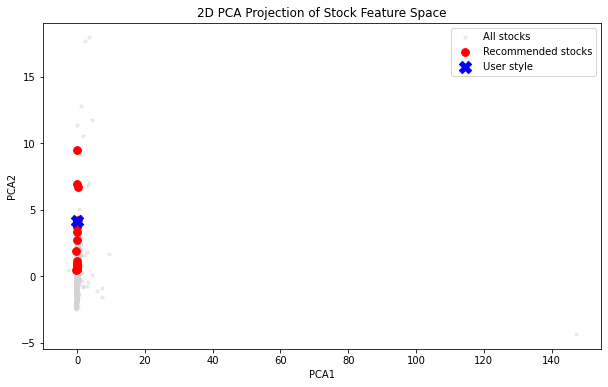

In [12]:
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

# -----------------------------
# Recompute recommendations
# -----------------------------
recs = recommend_stocks(example_holdings, top_k=20)

# -----------------------------
# PCA on the scaled features
# -----------------------------
pca = PCA(n_components=2)
coords = pca.fit_transform(X_scaled)

stock_features["pca1"] = coords[:, 0]
stock_features["pca2"] = coords[:, 1]

# -----------------------------
# Mark recommended stocks inside stock_features
# -----------------------------
stock_features["similarity"] = 0.0
# align on Symbol (not on the index)
sim_by_symbol = recs.set_index("Symbol")["similarity"]
stock_features.loc[
    stock_features["Symbol"].isin(sim_by_symbol.index),
    "similarity"
] = stock_features.loc[
    stock_features["Symbol"].isin(sim_by_symbol.index),
    "Symbol"
].map(sim_by_symbol)

# subset of stock_features for the recs (used for red points)
recs_plot = stock_features[stock_features["Symbol"].isin(recs["Symbol"])]

# -----------------------------
# User style vector (average of holdings) in PCA space
# -----------------------------
indices = [symbol_to_idx[s] for s in example_holdings if s in symbol_to_idx]
user_vec = X_scaled[indices].mean(axis=0, keepdims=True)
user_vec_pca = pca.transform(user_vec)[0]

# -----------------------------
# Plot
# -----------------------------
plt.figure(figsize=(10, 6))

# all stocks in light grey
plt.scatter(
    stock_features["pca1"], stock_features["pca2"],
    c="lightgray", alpha=0.4, s=10, label="All stocks"
)

# recommended stocks in red
plt.scatter(
    recs_plot["pca1"], recs_plot["pca2"],
    c="red", s=60, label="Recommended stocks"
)

# user style as a blue X
plt.scatter(
    user_vec_pca[0], user_vec_pca[1],
    c="blue", s=150, marker="X", label="User style"
)

plt.title("2D PCA Projection of Stock Feature Space")
plt.xlabel("PCA1")
plt.ylabel("PCA2")
plt.legend()
plt.show()


In [13]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Recompute recommendations
recs = recommend_stocks(example_holdings, top_k=20)

# --- PCA on feature space ---
pca = PCA(n_components=2)
coords = pca.fit_transform(X_scaled)

stock_features["pca1"] = coords[:, 0]
stock_features["pca2"] = coords[:, 1]

# Reattach clean Sector label for plotting
stock_features_with_sector = stock_features.merge(
    meta_small[["symbol", "Sector"]],
    left_on="Symbol",
    right_on="symbol",
    how="left"
)
stock_features_with_sector.drop(columns=["symbol"], inplace=True)

# Mark recommendations
sim_by_symbol = recs.set_index("Symbol")["similarity"]
stock_features_with_sector["similarity"] = stock_features_with_sector["Symbol"].map(sim_by_symbol).fillna(0.0)

# Subset: only recommended rows
recs_plot = stock_features_with_sector[stock_features_with_sector["Symbol"].isin(recs["Symbol"])]

# User style (same as in recommend_stocks)
indices = [symbol_to_idx[s] for s in example_holdings if s in symbol_to_idx]
user_vec = X_scaled[indices].mean(axis=0, keepdims=True)
user_vec_pca = pca.transform(user_vec)[0]


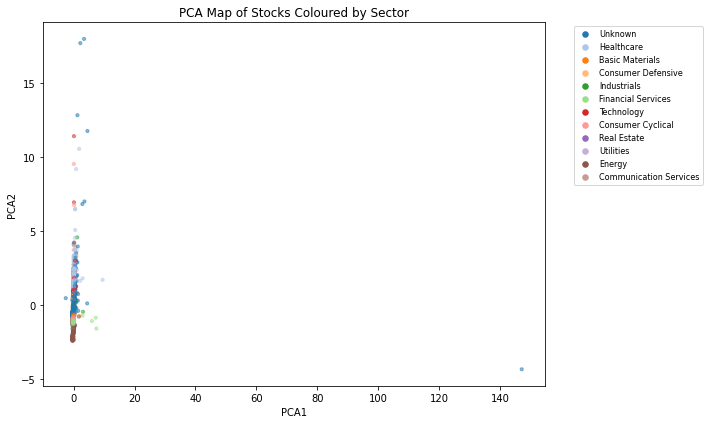

In [15]:
plt.figure(figsize=(10, 6))

# Decide a color per sector
sectors = stock_features_with_sector["Sector"].fillna("Unknown").unique()
colors = plt.cm.tab20(range(len(sectors)))  # up to 20 sectors

sector_to_color = {sec: colors[i] for i, sec in enumerate(sectors)}
point_colors = stock_features_with_sector["Sector"].fillna("Unknown").map(sector_to_color)

plt.scatter(
    stock_features_with_sector["pca1"],
    stock_features_with_sector["pca2"],
    c=point_colors,
    alpha=0.5,
    s=10
)

for sec in sectors:
    plt.scatter([], [], c=[sector_to_color[sec]], label=sec, s=30)

plt.title("PCA Map of Stocks Coloured by Sector")
plt.xlabel("PCA1")
plt.ylabel("PCA2")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()



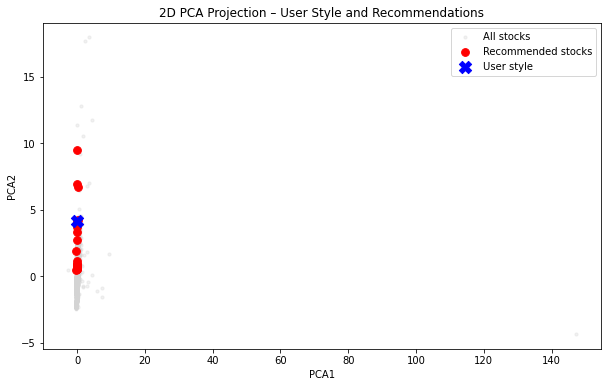

In [16]:
plt.figure(figsize=(10, 6))

# All stocks in light grey
plt.scatter(
    stock_features_with_sector["pca1"],
    stock_features_with_sector["pca2"],
    c="lightgray",
    alpha=0.3,
    s=10,
    label="All stocks"
)

# Recommended stocks in red
plt.scatter(
    recs_plot["pca1"],
    recs_plot["pca2"],
    c="red",
    s=60,
    label="Recommended stocks"
)

# User style point in blue
plt.scatter(
    user_vec_pca[0],
    user_vec_pca[1],
    c="blue",
    s=150,
    marker="X",
    label="User style"
)

plt.title("2D PCA Projection – User Style and Recommendations")
plt.xlabel("PCA1")
plt.ylabel("PCA2")
plt.legend()
plt.show()


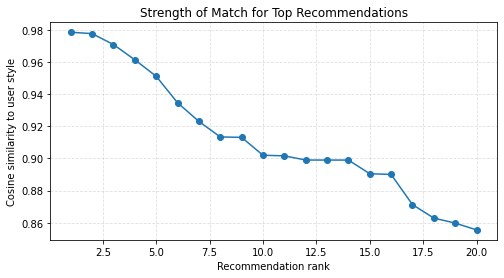

In [17]:
# Rec's similarities sorted
similarities_sorted = recs["similarity"].sort_values(ascending=False).reset_index(drop=True)

plt.figure(figsize=(8, 4))
plt.plot(similarities_sorted.index + 1, similarities_sorted.values, marker="o")
plt.xlabel("Recommendation rank")
plt.ylabel("Cosine similarity to user style")
plt.title("Strength of Match for Top Recommendations")
plt.grid(True, linestyle="--", alpha=0.4)
plt.show()


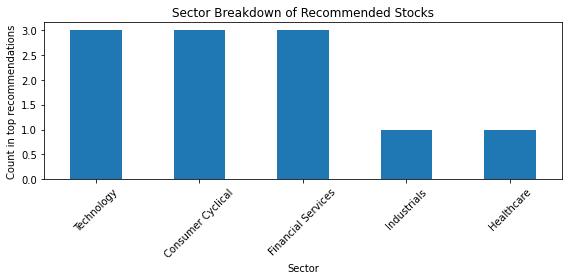

In [18]:
sector_counts = recs_plot["Sector"].value_counts()

plt.figure(figsize=(8, 4))
sector_counts.plot(kind="bar")
plt.title("Sector Breakdown of Recommended Stocks")
plt.xlabel("Sector")
plt.ylabel("Count in top recommendations")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [21]:
# features we use to explain "style"
STYLE_FEATURES = ["mean_ret", "vol_ret", "mom_1m", "mom_3m", "mom_12m", "avg_dollar_vol"]

def _describe_relative(value, ref, tol=0.15):
    """
    Compare value vs reference (user style).
    tol is a tolerance as a fraction of |ref|.
    """
    if pd.isna(value) or pd.isna(ref):
        return "unknown"

    if ref == 0:
        diff = value
        if diff > 0:
            return "higher"
        elif diff < 0:
            return "lower"
        else:
            return "similar"

    diff_pct = (value - ref) / abs(ref)
    if diff_pct > tol:
        return "higher"
    elif diff_pct < -tol:
        return "lower"
    else:
        return "similar"


def recommend_stocks(user_holdings, top_k=20):
    """
    user_holdings: list of ticker strings, e.g. ["AAPL", "MSFT"]
    top_k: number of recommendations
    """

    # ---- 1) Show user input portfolio
    print("User holdings:", user_holdings)

    # keep only holdings present in our universe
    in_universe = [s for s in user_holdings if s in symbol_to_idx]
    indices = [symbol_to_idx[s] for s in in_universe]
    if not indices:
        raise ValueError("None of the user holdings are in the dataset.")

    # ---- 2) User style in scaled space (for similarity)
    user_vec_scaled = X_scaled[indices].mean(axis=0, keepdims=True)

    # ---- 3) Similarity between user style and every stock
    sim = cosine_similarity(user_vec_scaled, X_scaled).flatten()

    # ---- 4) Build base DataFrame with scores + company names
    rec_df = stock_features.copy()
    rec_df["similarity"] = sim

    # add company name from metadata
    rec_df = rec_df.merge(
        meta_small[["symbol", "security_name", "Sector"]],
        left_on="Symbol",
        right_on="symbol",
        how="left"
    ).drop(columns=["symbol"])

    # ---- 5) Compute user style in ORIGINAL feature space (for explanations)
    user_style = (
        stock_features
        .set_index("Symbol")
        .loc[in_universe, STYLE_FEATURES]
        .mean()
    )

    # ---- 6) Build a human-readable explanation for each recommended stock
    explanations = []
    for _, row in rec_df.iterrows():
        sym = row["Symbol"]
        name = row.get("security_name", "Unknown company")

        # sector vs user sectors
        stock_sector = row.get("Sector", "Unknown")

        vol_rel  = _describe_relative(row.get("vol_ret"),  user_style.get("vol_ret"))
        mom3_rel = _describe_relative(row.get("mom_3m"),  user_style.get("mom_3m"))
        mom12_rel = _describe_relative(row.get("mom_12m"), user_style.get("mom_12m"))
        liq_rel  = _describe_relative(row.get("avg_dollar_vol"), user_style.get("avg_dollar_vol"))

        sentence = (
            f"{sym} ({name}) is {vol_rel} volatility, "
            f"{mom3_rel} 3-month momentum and {mom12_rel} 12-month momentum "
            f"compared to your average holdings, with {liq_rel} liquidity, "
            f"in the {stock_sector} sector."
        )
        explanations.append(sentence)

    rec_df["explanation"] = explanations

    # ---- 7) Remove stocks already held by the user
    rec_df = rec_df[~rec_df["Symbol"].isin(in_universe)]

    # ---- 8) Sort by similarity and keep top_k
    recs = rec_df.sort_values("similarity", ascending=False).head(top_k)

    # columns to display
    cols = ["Symbol", "security_name", "Sector", "similarity", "explanation"]
    cols += [c for c in rec_df.columns if c.startswith("Sector_")]  # keep one-hots if you want

    return recs[cols]


In [26]:
example_holdings = ["A", "RACE", "AA"]
recs = recommend_stocks(example_holdings, top_k=10)
print(recs)


User holdings (with company names):
  Symbol                            security_name             Sector
0      A  Agilent Technologies, Inc. Common Stock         Healthcare
1   RACE               Ferrari N.V. Common Shares  Consumer Cyclical
2     AA           Alcoa Corporation Common Stock    Basic Materials
(     Symbol                                      security_name  \
5246   VALE  VALE S.A.  American Depositary Shares Each Rep...   
1477    DOW                              Dow Inc. Common Stock   
1859    FCX                Freeport-McMoRan, Inc. Common Stock   
3085    LYB  LyondellBasell Industries NV Ordinary Shares C...   
4546    SHW        Sherwin-Williams Company (The) Common Stock   
4074    PPG                  PPG Industries, Inc. Common Stock   
311     APD      Air Products and Chemicals, Inc. Common Stock   
3256    MLM       Martin Marietta Materials, Inc. Common Stock   
2984    LIN                           Linde plc Ordinary Share   
1279   CTVA                

In [23]:
# Save to Excel
output_path = "/Users/yasmineleuch/Downloads/data_cleaned/stock_recommendations.xlsx"
recs.to_excel(output_path, index=False)

print(f"Excel file saved to: {output_path}")


Excel file saved to: /Users/yasmineleuch/Downloads/data_cleaned/stock_recommendations.xlsx


In [24]:
STYLE_FEATURES = ["mean_ret", "vol_ret", "mom_1m", "mom_3m", "mom_12m", "avg_dollar_vol"]

def _describe_relative(value, ref, tol=0.15):
    if pd.isna(value) or pd.isna(ref):
        return "unknown"
    if ref == 0:
        diff = value
        if diff > 0:
            return "higher"
        elif diff < 0:
            return "lower"
        else:
            return "similar"
    diff_pct = (value - ref) / abs(ref)
    if diff_pct > tol:
        return "higher"
    elif diff_pct < -tol:
        return "lower"
    else:
        return "similar"


def recommend_stocks(user_holdings, top_k=20):
    """
    Returns:
      recs_df: recommendations with company names + explanation
      user_df: user's holdings with Symbol + company name
    """

    # Keep only holdings present in universe
    in_universe = [s for s in user_holdings if s in symbol_to_idx]
    if not in_universe:
        raise ValueError("None of the user holdings are in the dataset.")

    # ---- USER HOLDINGS TABLE (with names) ----
    user_df = pd.DataFrame({"Symbol": in_universe})
    user_df = user_df.merge(
        meta_small[["symbol", "security_name", "Sector"]],
        left_on="Symbol",
        right_on="symbol",
        how="left"
    ).drop(columns=["symbol"])

    print("User holdings (with company names):")
    print(user_df[["Symbol", "security_name", "Sector"]])

    # ---- USER STYLE VEC (scaled) ----
    indices = [symbol_to_idx[s] for s in in_universe]
    user_vec_scaled = X_scaled[indices].mean(axis=0, keepdims=True)

    # ---- SIMILARITY TO ALL STOCKS ----
    sim = cosine_similarity(user_vec_scaled, X_scaled).flatten()

    rec_df = stock_features.copy()
    rec_df["similarity"] = sim

    # Add company name + sector
    rec_df = rec_df.merge(
        meta_small[["symbol", "security_name", "Sector"]],
        left_on="Symbol",
        right_on="symbol",
        how="left"
    ).drop(columns=["symbol"])

    # USER STYLE IN ORIGINAL FEATURE SPACE (for explanations)
    user_style = (
        stock_features
        .set_index("Symbol")
        .loc[in_universe, STYLE_FEATURES]
        .mean()
    )

    explanations = []
    for _, row in rec_df.iterrows():
        sym = row["Symbol"]
        name = row.get("security_name", "Unknown company")
        sector = row.get("Sector", "Unknown")

        vol_rel   = _describe_relative(row.get("vol_ret"),          user_style.get("vol_ret"))
        mom3_rel  = _describe_relative(row.get("mom_3m"),           user_style.get("mom_3m"))
        mom12_rel = _describe_relative(row.get("mom_12m"),          user_style.get("mom_12m"))
        liq_rel   = _describe_relative(row.get("avg_dollar_vol"),   user_style.get("avg_dollar_vol"))

        sentence = (
            f"{sym} ({name}) is {vol_rel} volatility, "
            f"{mom3_rel} 3-month momentum and {mom12_rel} 12-month momentum "
            f"compared to your average holdings, with {liq_rel} liquidity, "
            f"in the {sector} sector."
        )
        explanations.append(sentence)

    rec_df["explanation"] = explanations

    # Remove already-held stocks
    rec_df = rec_df[~rec_df["Symbol"].isin(in_universe)]

    # Sort + select columns
    recs = rec_df.sort_values("similarity", ascending=False).head(top_k)

    cols = ["Symbol", "security_name", "Sector", "similarity", "explanation"]
    cols += [c for c in rec_df.columns if c.startswith("Sector_")]

    recs = recs[cols]

    return recs, user_df


In [27]:
example_holdings = ["A", "RACE", "AA"]

recs, user_df = recommend_stocks(example_holdings, top_k=10)

print("\nUser portfolio table:\n", user_df)
print("\nRecommendations:\n", recs.head())


User holdings (with company names):
  Symbol                            security_name             Sector
0      A  Agilent Technologies, Inc. Common Stock         Healthcare
1   RACE               Ferrari N.V. Common Shares  Consumer Cyclical
2     AA           Alcoa Corporation Common Stock    Basic Materials

User portfolio table:
   Symbol                            security_name             Sector
0      A  Agilent Technologies, Inc. Common Stock         Healthcare
1   RACE               Ferrari N.V. Common Shares  Consumer Cyclical
2     AA           Alcoa Corporation Common Stock    Basic Materials

Recommendations:
      Symbol                                      security_name  \
5246   VALE  VALE S.A.  American Depositary Shares Each Rep...   
1477    DOW                              Dow Inc. Common Stock   
1859    FCX                Freeport-McMoRan, Inc. Common Stock   
3085    LYB  LyondellBasell Industries NV Ordinary Shares C...   
4546    SHW        Sherwin-Williams Com